# scikit-learn Perceptron — Near-Separable Data

Train `sklearn.linear_model.Perceptron` on a 2-D `make_classification` dataset; confusion matrix, accuracy and decision boundary.

# 2.a.1

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_classification
from sklearn import datasets

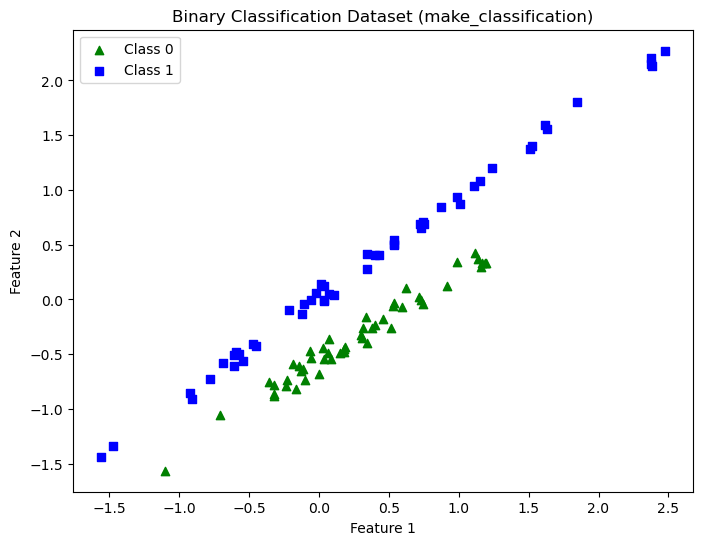

In [2]:
X, y = make_classification(
    n_samples=100,
    n_features=2,
    n_informative=2,
    n_redundant=0,
    n_clusters_per_class=1,
    class_sep=0.3,
    random_state=42
)

plt.figure(figsize=(8, 6))
plt.scatter(X[y == 0, 0], X[y == 0, 1], c='green', marker='^', label='Class 0')
plt.scatter(X[y == 1, 0], X[y == 1, 1], c='blue', marker='s', label='Class 1')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Binary Classification Dataset (make_classification)')
plt.legend()
plt.show()

# 2.a.2

In [3]:
y_shape = y.reshape(100,1)
X_train, X_test, Y_train, Y_test = train_test_split(X, y, test_size=0.3,random_state=420)

# 2.a.3

In [4]:
from sklearn.linear_model import Perceptron

clf = Perceptron()

clf.fit(X_train,Y_train)

print("Classifier Weights: ", clf.coef_)
print("Classifier Constant:", clf.intercept_)

Classifier Weights:  [[-3.19699635  3.92434269]]
Classifier Constant: [1.]


In [5]:
from sklearn.metrics import confusion_matrix

y_pred = clf.predict(X_test)
confusion_matrix(Y_test, y_pred)

array([[12,  0],
       [ 0, 18]])

# 2.a.4

In [6]:
from sklearn.metrics import accuracy_score

accuracy_score(Y_test, y_pred)

1.0

# 2.a.5

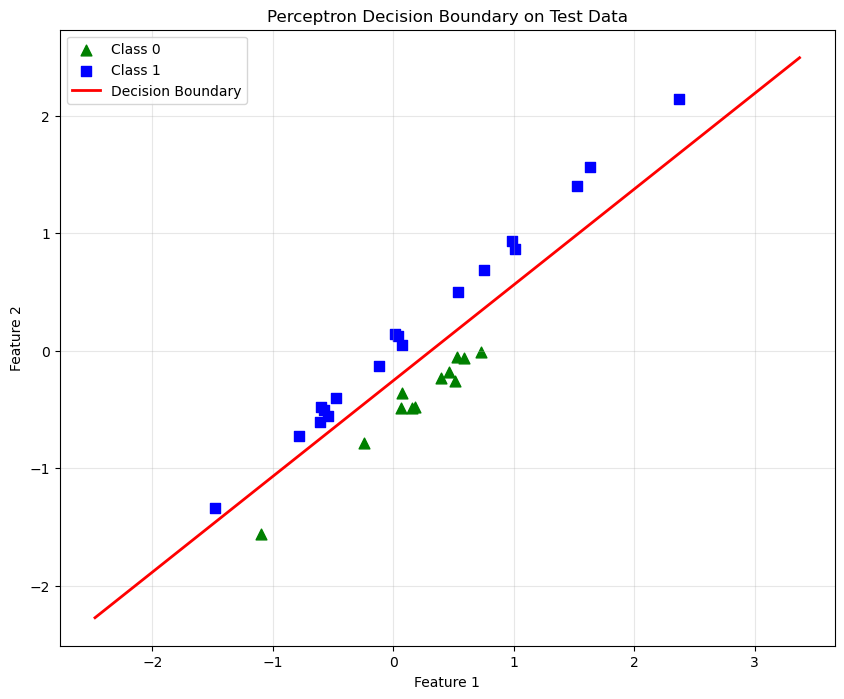

In [7]:
plt.figure(figsize=(10, 8))

plt.scatter(X_test[Y_test == 0, 0], X_test[Y_test == 0, 1], c='green', marker='^', s=60, label='Class 0')
plt.scatter(X_test[Y_test == 1, 0], X_test[Y_test == 1, 1], c='blue', marker='s', s=60, label='Class 1')

xx = np.linspace(X_test[:, 0].min()-1, X_test[:, 0].max()+1, 100)
yy = (-clf.coef_[0][0] * xx - clf.intercept_[0]) / clf.coef_[0][1]
plt.plot(xx, yy, 'r-', linewidth=2, label='Decision Boundary')

plt.grid(True, alpha=0.3)
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Perceptron Decision Boundary on Test Data')
plt.legend()

plt.show()